# Loan Default Prediction with Deep Learning

Predicting which applicants will have trouble repaying a loan, using a feed-forward neural network (TensorFlow/Keras) on 307,511 loan applications with 120 features. The classes are heavily imbalanced (~8% defaults), so the model is evaluated on recall for defaulters and ROC-AUC rather than accuracy.

Data: `application_train.csv` from the Kaggle [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk/data) competition, saved as `loan_data.csv` (see README).

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 1: Load the dataset given
df = pd.read_csv('loan_data.csv')
df.drop(['SK_ID_CURR'], axis=1, inplace=True)
print(df.head())

   TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  \
0       1         Cash loans           M            N               Y   
1       0         Cash loans           F            N               N   
2       0    Revolving loans           M            Y               Y   
3       0         Cash loans           F            N               Y   
4       0         Cash loans           M            N               Y   

   CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0             0          202500.0    406597.5      24700.5         351000.0   
1             0          270000.0   1293502.5      35698.5        1129500.0   
2             0           67500.0    135000.0       6750.0         135000.0   
3             0          135000.0    312682.5      29686.5         297000.0   
4             0          121500.0    513000.0      21865.5         513000.0   

   ... FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...  

In [3]:
# Step 2: Check for null values
df.isnull().sum()

TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
FLAG_OWN_REALTY                   0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 121, dtype: int64

In [4]:
# Handling missing values
from sklearn.impute import SimpleImputer

# For numeric columns
numeric_imputer = SimpleImputer(strategy='median')
# For categorical columns
categorical_imputer = SimpleImputer(strategy='most_frequent')

numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

df[numeric_columns] = numeric_imputer.fit_transform(df[numeric_columns])
df[categorical_columns] = categorical_imputer.fit_transform(df[categorical_columns])

In [5]:
df.isnull().sum()

TARGET                        0
NAME_CONTRACT_TYPE            0
CODE_GENDER                   0
FLAG_OWN_CAR                  0
FLAG_OWN_REALTY               0
                             ..
AMT_REQ_CREDIT_BUREAU_DAY     0
AMT_REQ_CREDIT_BUREAU_WEEK    0
AMT_REQ_CREDIT_BUREAU_MON     0
AMT_REQ_CREDIT_BUREAU_QRT     0
AMT_REQ_CREDIT_BUREAU_YEAR    0
Length: 121, dtype: int64

In [6]:
# Step 3: Print the percentage of default to a payer of the dataset for the TARGET column


defaulters=(df.TARGET==1).sum()
payers=(df.TARGET==0).sum()
default_payer = defaulters/payers*100
print("percentage of default to payer is :", default_payer)

percentage of default to payer is : 8.781828601345662


In [7]:
# Step 4: Balance the dataset if the data is imbalanced
df["TARGET"].value_counts()

TARGET
0.0    282686
1.0     24825
Name: count, dtype: int64

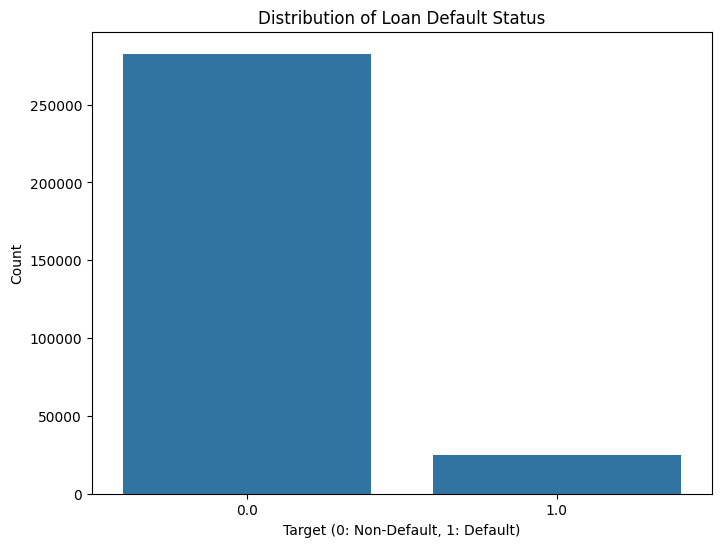

In [8]:
# Step 5: Plot the imbalanced data
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='TARGET')
plt.title('Distribution of Loan Default Status')
plt.xlabel('Target (0: Non-Default, 1: Default)')
plt.ylabel('Count')
plt.show()

In [9]:
# Step 6: Encode categorical variables, split the data, then balance the TRAINING set with SMOTE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter

# Create a copy of the dataframe to avoid modifying the original
df_encoded = df.copy()

# List of categorical columns to encode
categorical_columns = df_encoded.select_dtypes(include=['object']).columns

# Encode categorical variables
le = LabelEncoder()
for column in categorical_columns:
    df_encoded[column] = le.fit_transform(df_encoded[column])

# Separate features and target
X = df_encoded.drop('TARGET', axis=1)
y = df_encoded['TARGET']

# Split BEFORE oversampling: the test set keeps the real ~8% default rate and contains no synthetic rows
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=25, stratify=y)

# Hold out a validation set (also real data) for early stopping
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.1, random_state=25, stratify=y_train)

# Keep the real training data for the class-weight comparison in Step 8
x_train_orig, y_train_orig = x_train.copy(), y_train.copy()

# Apply SMOTE to the training data only
smote = SMOTE(random_state=25)
x_train, y_train = smote.fit_resample(x_train, y_train)

print("Training class distribution after SMOTE:", Counter(y_train))
print("Validation class distribution:", Counter(y_val))
print("Test class distribution:", Counter(y_test))

Training class distribution after SMOTE: Counter({0.0: 190812, 1.0: 190812})
Validation class distribution: Counter({0.0: 21202, 1.0: 1862})
Test class distribution: Counter({0.0: 70672, 1.0: 6206})


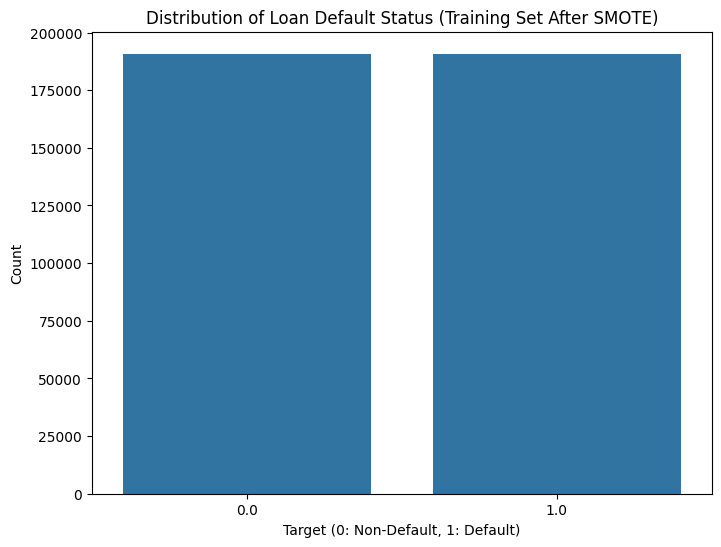

In [10]:
# Step 7: Plot the balanced training data
plt.figure(figsize=(8, 6))
sns.countplot(x=y_train)
plt.title('Distribution of Loan Default Status (Training Set After SMOTE)')
plt.xlabel('Target (0: Non-Default, 1: Default)')
plt.ylabel('Count')
plt.show()

In [11]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_val=scaler.transform(x_val)
x_test=scaler.transform(x_test)

In [12]:
# Build the Deep Learning Model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input

In [13]:
model = Sequential()
model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(256, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(64, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(1, activation="sigmoid"))

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        30,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,193 (282.00 KB)

 Trainable params: 72,193 (282.00 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop when validation AUC stops improving and keep the best weights
early_stop = EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True)

history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30, batch_size=256,
                    callbacks=[early_stop], verbose=2)

Epoch 1/30


1491/1491 - 3s - 2ms/step - accuracy: 0.7870 - auc: 0.8689 - loss: 0.4548 - val_accuracy: 0.8336 - val_auc: 0.6837 - val_loss: 0.4206


Epoch 2/30


1491/1491 - 2s - 2ms/step - accuracy: 0.8375 - auc: 0.9153 - loss: 0.3662 - val_accuracy: 0.8539 - val_auc: 0.6806 - val_loss: 0.3796


Epoch 3/30


1491/1491 - 2s - 2ms/step - accuracy: 0.8532 - auc: 0.9278 - loss: 0.3357 - val_accuracy: 0.8701 - val_auc: 0.6897 - val_loss: 0.3565


... (16 outputs left out)

Epoch 12/30


1491/1491 - 2s - 2ms/step - accuracy: 0.8932 - auc: 0.9547 - loss: 0.2570 - val_accuracy: 0.8930 - val_auc: 0.7114 - val_loss: 0.3035


Epoch 13/30


1491/1491 - 2s - 2ms/step - accuracy: 0.8941 - auc: 0.9554 - loss: 0.2548 - val_accuracy: 0.8978 - val_auc: 0.7069 - val_loss: 0.2946


In [17]:
pred_proba = model.predict(x_test, verbose=0).ravel()
pred = (pred_proba > 0.5).astype(int)

In [18]:
from sklearn.metrics import confusion_matrix,classification_report
cm = confusion_matrix(y_test, pred)
print(cm)
print(classification_report(y_test, pred, target_names=["Repaid", "Default"]))

[[67936  2736]
 [ 5568   638]]
              precision    recall  f1-score   support

      Repaid       0.92      0.96      0.94     70672
     Default       0.19      0.10      0.13      6206

    accuracy                           0.89     76878
   macro avg       0.56      0.53      0.54     76878
weighted avg       0.86      0.89      0.88     76878



In [19]:
# Sensitivity (recall for defaulters) = TP / (TP + FN)
TP = cm[1,1]
FN = cm[1,0]
print("Sensitivity:", TP/(TP+FN))

Sensitivity: 0.102803738317757


In [20]:
# Calculate the area under the receiver operating characteristics curve (uses predicted probabilities)
from sklearn.metrics import roc_auc_score

print("ROC-AUC:", roc_auc_score(y_test, pred_proba))

ROC-AUC: 0.694212877858676


## Step 8: Improving the model: class weights and threshold tuning

With SMOTE, the network scores well on the synthetic training rows but catches only about 1 in 10 real defaulters at the default 0.5 threshold. Below, the same architecture is trained on the **real** (non-oversampled) training data, with class weights to penalize missed defaults. The decision threshold is then chosen on the validation set, so the test set stays untouched.

In [21]:
# Step 8a: Same architecture, trained on real data with balanced class weights instead of SMOTE
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train_orig)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

cw_model = Sequential([
    Input(shape=(x_train.shape[1],)),
    Dense(256, activation="relu"), Dropout(0.3),
    Dense(128, activation="relu"), Dropout(0.3),
    Dense(64, activation="relu"), Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
cw_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=[tf.keras.metrics.AUC(name="auc")])

cw_model.fit(scaler.transform(x_train_orig), y_train_orig, validation_data=(x_val, y_val), epochs=30, batch_size=256,
             class_weight=class_weight,
             callbacks=[EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True)], verbose=2)

cw_proba = cw_model.predict(x_test, verbose=0).ravel()
print("ROC-AUC (class weights):", roc_auc_score(y_test, cw_proba))

cw_pred = (cw_proba > 0.5).astype(int)
print(confusion_matrix(y_test, cw_pred))
print(classification_report(y_test, cw_pred, target_names=["Repaid", "Default"]))

Class weights: {0: np.float64(0.5439097121774312), 1: np.float64(6.1935012233693385)}


Epoch 1/30


811/811 - 2s - 2ms/step - auc: 0.7083 - loss: 0.6291 - val_auc: 0.7430 - val_loss: 0.6260


Epoch 2/30


811/811 - 1s - 2ms/step - auc: 0.7319 - loss: 0.6101 - val_auc: 0.7455 - val_loss: 0.6060


Epoch 3/30


... (16 outputs left out)

811/811 - 1s - 2ms/step - auc: 0.7551 - loss: 0.5882 - val_auc: 0.7487 - val_loss: 0.5982


Epoch 12/30


811/811 - 1s - 2ms/step - auc: 0.7558 - loss: 0.5872 - val_auc: 0.7493 - val_loss: 0.5932


ROC-AUC (class weights): 0.7378971196982245
[[49094 21578]
 [ 2120  4086]]
              precision    recall  f1-score   support

      Repaid       0.96      0.69      0.81     70672
     Default       0.16      0.66      0.26      6206

    accuracy                           0.69     76878
   macro avg       0.56      0.68      0.53     76878
weighted avg       0.89      0.69      0.76     76878



In [22]:
# Step 8b: Choose the decision threshold that maximizes F1 for defaulters on the VALIDATION set
from sklearn.metrics import precision_recall_curve

val_proba = cw_model.predict(x_val, verbose=0).ravel()
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_threshold = thr[np.argmax(f1[:-1])]
print("Best threshold on validation set:", round(float(best_threshold), 3))

tuned_pred = (cw_proba > best_threshold).astype(int)
print(confusion_matrix(y_test, tuned_pred))
print(classification_report(y_test, tuned_pred, target_names=["Repaid", "Default"]))

Best threshold on validation set: 0.636
[[62380  8292]
 [ 3822  2384]]
              precision    recall  f1-score   support

      Repaid       0.94      0.88      0.91     70672
     Default       0.22      0.38      0.28      6206

    accuracy                           0.84     76878
   macro avg       0.58      0.63      0.60     76878
weighted avg       0.88      0.84      0.86     76878



## Results summary (test set: 76,878 real applications, 6,206 defaults)

| Approach | ROC-AUC | Recall (Default) | Precision (Default) |
|---|---|---|---|
| SMOTE, 0.5 threshold | 0.694 | 0.10 | 0.19 |
| **Class weights, 0.5 threshold** | **0.738** | **0.66** | 0.16 |
| Class weights, F1-tuned threshold (0.636) | 0.738 | 0.38 | 0.22 |

**Takeaways**
- SMOTE on 120 mixed-type features generated synthetic defaulters that didn't look like real ones. The network learned them easily (0.95 training AUC) but generalized poorly to real applicants.
- Class weighting on real data raised ROC-AUC by 0.04 and caught 6.5× more defaulters at the same threshold.
- The threshold is a business decision: 0.5 catches two-thirds of defaulters but flags many good applicants; the F1-tuned threshold trades recall for fewer false alarms.
- Next steps: gradient-boosted trees (e.g., LightGBM), one-hot encoding for nominal categories, and the bureau/previous-application tables from the full Home Credit dataset.